In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [17]:
# Last inn data
df = pd.read_csv('./datasets/Titanic-Dataset.csv')

# Databehandling / "Data wrangling"
#df['Age'] = df['Age'].fillna(df['Age'].median()) # Sett inn median alder, der alder mangler
#df = df.dropna(subset=['Age'])  # Evt fjern de som mangler alder?

# Raden 'sex' har verdiene male, eller female. "Mapper" veridene om til tall, slik at dataen kan behandles.
df['Sex_'] = df['Sex'].map({'male': 0, 'female': 1}) 

# Regner ut familiestørrelse ved å slå sammen antall barn/ektefelle og foreldre/barn
df['FamilySize'] = df['SibSp'] + df['Parch']

# Antall rader i datasettet
print(df['PassengerId'].count())

variabler = ['Survived', 'Pclass', 'Age', 'Fare', 'FamilySize']
statistikk = df[variabler].agg(['mean', 'median', 'std', 'var', 'min', 'max']).T
print (statistikk.round(2))

891
             mean  median    std      var   min     max
Survived     0.38    0.00   0.49     0.24  0.00    1.00
Pclass       2.31    3.00   0.84     0.70  1.00    3.00
Age         29.70   28.00  14.53   211.02  0.42   80.00
Fare        32.20   14.45  49.69  2469.44  0.00  512.33
FamilySize   0.90    0.00   1.61     2.60  0.00   10.00


Text(0, 0.5, 'Antall')

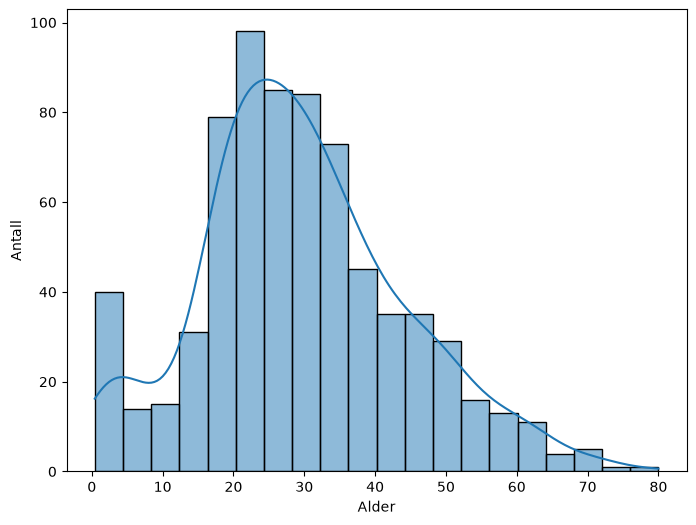

In [18]:
plt.figure(figsize=(8, 6))
sns.histplot(df['Age'], kde=True)
plt.xlabel('Alder')
plt.ylabel('Antall')

Text(0, 0.5, 'Alder')

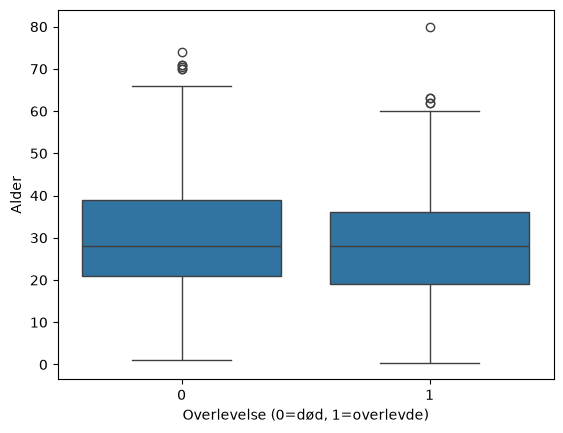

In [21]:
sns.boxplot(x='Survived', y='Age', data=df)
plt.xlabel('Overlevelse (0=død, 1=overlevde)')
plt.ylabel('Alder')

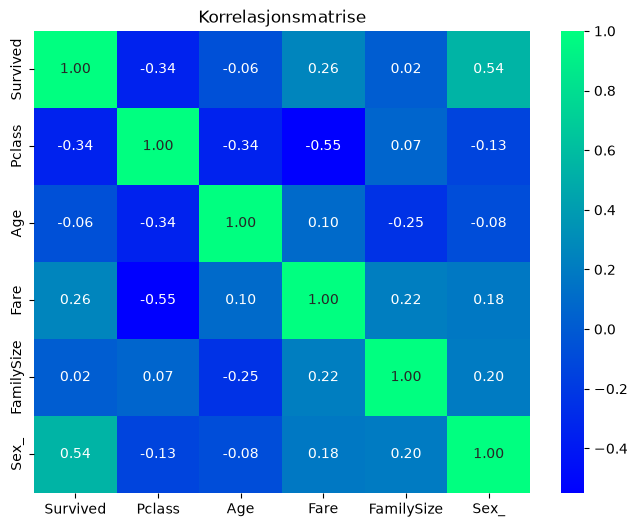

In [15]:
# Korrelasjonsmatrise

plt.figure(figsize=(8, 6))
sns.heatmap(df[['Survived', 'Pclass', 'Age', 'Fare', 'FamilySize', 'Sex_']].corr(), annot=True, cmap='winter', fmt=".2f")
plt.title('Korrelasjonsmatrise')
plt.show()

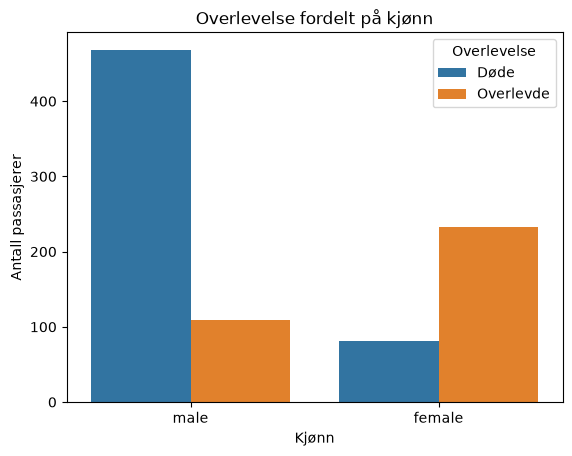

In [16]:
sns.countplot(x='Sex', hue='Survived', data=df)

plt.xlabel('Kjønn')
plt.ylabel('Antall passasjerer')
plt.title('Overlevelse fordelt på kjønn')
plt.legend(title='Overlevelse', labels=['Døde', 'Overlevde'])

plt.show()